### Agentic RAG with Langgraph


In [1]:
import os
from typing import TypedDict, List
from langchain_community.vectorstores import FAISS
from langchain_groq import ChatGroq
from langchain_huggingface import HuggingFaceEmbeddings
from langgraph.graph import StateGraph, END
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document


C:\Users\Saif\AppData\Local\Temp\ipykernel_12284\3016512922.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


In [2]:
import os
from dotenv import find_dotenv, load_dotenv
load_dotenv(find_dotenv(usecwd=True))

True

In [3]:
from getpass import getpass
#SET UP your api key
if not os.getenv("GROQ_API_KEY"):
    raise ValueError("GROQ_API_KEY was not loaded; check the .env path and variable name.")

llm = ChatGroq(
    model_name="openai/gpt-oss-20b",
    temperature=0.0,
    max_tokens=1024,
)

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [4]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.7', 'langchain': '1.4.2'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001AD0E70CB60>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001AD0E7A1BE0>, model_name='openai/gpt-oss-20b', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********'), max_tokens=1024)

### State Definition]


In [5]:
class AgentState(TypedDict):
    document = List[Document]
    question = str
    answer = str
    ask_retrieval = bool

In [6]:
sample_texts = [
    "LangGraph is a library for building stateful, multi-actor applications with LLMs. It extends LangChain with the ability to coordinate multiple chains across multiple steps of computation in a cyclic manner.",
    "RAG (Retrieval-Augmented Generation) is a technique that combines information retrieval with text generation. It retrieves relevant documents and uses them to provide context for generating more accurate responses.",
    "Vector databases store high-dimensional vectors and enable efficient similarity search. They are commonly used in RAG systems to find relevant documents based on semantic similarity.",
    "Agentic systems are AI systems that can take actions, make decisions, and interact with their environment autonomously. They often use planning and reasoning capabilities."
]


documents = [Document(page_content=text) for text in sample_texts]

#Create Vector Store
vectorstore = FAISS.from_documents(documents, embeddings)
retriever = vectorstore.as_retriever(search_kwargs={"k": 3})

### Agent Function

In [7]:
def decide_retrieval(state : AgentState) -> AgentState:
     """
     Decide if we need to retrieve documents based on the question
     """
     question = state["question"]
     # Simple heuristic: if question contains certain keywords, retrieve
     retrieval_keywords = ["what", "how", "explain", "describe", "tell me"]
     needs_retrieval = any(text in question.lower() for text in retrieval_keywords)

     return {**state,needs_retrieval: "needs_retrieval"}

In [8]:
def retrieve_documents(state : AgentState) -> AgentState:
    """
    Retrieve relevant documents based on the question
    """
    question = state["question"]
    documents = retriever.invoke(question) # invoking context using retriever for question
    
    return {**state, "documents": documents}

In [16]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

def generate(state : AgentState) -> AgentState:
    """
    Generate an answer using the retrieved documents or direct response
    """
    question = state["question"]
    docum = state.get("documents", [])

    if docum:
        # RAG approach: use documents as context
        context = "\n\n".join([doc.page_content for doc in docum])
        prompt = ChatPromptTemplate.from_template(
            """Answer the question using only the context below.
        If the context doesn't contain the answer, say you don't know.

        Context:
        {context}

        Question: {question}
        
        Answer : """
        )

    else:
        # Direct response without retrieval
        prompt = f"Answer the following question: {question}"
    
    response = llm.invoke(prompt)
    answer = response.content
    return {**state, "answer": answer}

### COnditional LOgic

In [17]:
def should_retrieve(state: AgentState) -> str:
    """
    Determine the next step based on retrieval decision
    """
    if state["needs_retrieval"]:
        return "retrieve"
    else:
        return "generate"

### Build the Graph

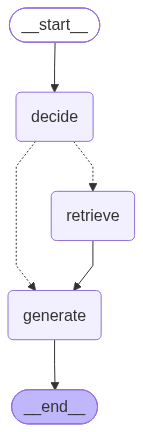

In [18]:
graph = StateGraph(AgentState)

graph.add_node("decide", decide_retrieval)
graph.add_node("retrieve", retrieve_documents)
graph.add_node("generate", generate)

graph.set_entry_point("decide")

graph.add_conditional_edges(
    "decide",
    should_retrieve,
    {
        #Edge : Node
        "retrieve": "retrieve",
        "generate" : "generate"
    }
)

graph.add_edge("retrieve", "generate")
graph.add_edge("generate", END)

app = graph.compile()
app

### Test the Agentic system

In [19]:
def ask_question(question: str):
    """
    Helper function to ask a question and get an answer
    """
    initial_state = {
        "question": question,
        "documents": [],
        "answer": "",
        "needs_retrieval": False
    }
    
    result = app.invoke(initial_state)
    return result

In [ ]:

# Replace the placeholder with:
question1 = "What is LangGraph?"

# Also fix the state schema and node logic to match the actual keys:
class AgentState(TypedDict):
    question: str
    documents: List[Document]
    answer: str
    needs_retrieval: bool

def decide_retrieval(state: AgentState) -> AgentState:
    question = state["question"]
    retrieval_keywords = ["what", "how", "explain", "describe", "tell me"]
    needs_retrieval = any(text in question.lower() for text in retrieval_keywords)
    return {**state, "needs_retrieval": needs_retrieval}

def should_retrieve(state: AgentState) -> str:
    return "retrieve" if state.get("needs_retrieval", False) else "generate"

result1 = ask_question(question1)
result1
result1 = ask_question(question1)
result1

KeyError: 'question'

In [ ]:
# #DOnt run this for now 
# from langchain_core.prompts import ChatPromptTemplate
# from langchain_core.output_parsers import StrOutputParser

# prompt = ChatPromptTemplate.from_template(
#     """Answer the question using only the context below.
# If the context doesn't contain the answer, say you don't know.

# Context:
# {context}

# Question: {question}
# """
# )

# rag_chain = prompt | llm | StrOutputParser()

# def ask(question: str) -> str:
#     docs = retriever.invoke(question)
#     context = "\n\n".join(doc.page_content for doc in docs)
#     return rag_chain.invoke({"context": context, "question": question})

# print(ask("What is RAG?"))